<a href="https://colab.research.google.com/github/Renata-Nascimento/Projeto-U02-CD/blob/main/notebooks/08_analise_outliers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook 08 - Análise de Outliers e Impacto Social: O Dinheiro a Mais Virou Melhores Resultados?
**Tema Central:** Para onde vai o dinheiro do Estado nos municípios do RN? (2ª Unidade - Ciência de Dados - IMD/UFRN)  
*Autora:* Brenda Gomes (com dados integrados de Repasses SEFAZ-RN, Emendas Parlamentares Federais, Convênios Transferegov, INEP/IDEB, DATASUS e CadÚnico)  
*Pergunta Orientadora:* Municípios que fogem radicalmente do padrão de arrecadação (outliers de royalties ou de emendas) conseguem converter esse volume financeiro extraordinário em **melhores resultados sociais reais (educação, saúde e superação da pobreza)**?

## 1. Configuração do Ambiente e Carregamento da Base Consolidada

Carregamos a base mestre unificada do quadriênio 2020-2023 contendo todos os 167 municípios do Rio Grande do Norte (668 observações), com valores deflacionados para preços reais de 2023 (IPCA):
* **Repasses Obrigatórios (SEFAZ-RN):** ICMS, IPVA, IPI e Royalties;
* **Emendas Parlamentares Federais:** Emendas PIX + Emendas via Convênio (SICONV);
* **Convênios Ministeriais Puros:** Convênios federais executivos sem emenda parlamentar;
* **Indicadores Socioeconômicos:** População (Censo IBGE), PIB per capita e CadÚnico.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.ticker as ticker
import os

# Estilo visual padronizado
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.labelsize": 10,
    "figure.titlesize": 14,
    "figure.titleweight": "bold"
})

# Caminhos tolerantes para Colab e ambiente local
p_local = os.path.join("..", "saida", "base_completa_repasses_emendas_convenios_2020_2023.csv")
p_direto = os.path.join("saida", "base_completa_repasses_emendas_convenios_2020_2023.csv")
p_fallback = os.path.join("..", "saida", "base_com_emendas_2020_2023.csv")

if os.path.exists(p_direto):
    df = pd.read_csv(p_direto)
elif os.path.exists(p_local):
    df = pd.read_csv(p_local)
else:
    df = pd.read_csv(p_fallback)

print(f"Base carregada: {df.shape[0]} linhas e {df.shape[1]} colunas.")

# Criação do DataFrame Acumulado Quadrienal (2020-2023) por município
df_acumulado = df.groupby(["cod_ibge", "municipio", "mesorregiao", "porte"]).agg(
    populacao_media=("populacao", "mean"),
    pct_baixa_renda_media=("pct_baixa_renda", "mean"),
    pib_pc_medio=("pib_per_capita", "mean"),
    rep_total_real=("rep_total_real", "sum"),
    emendas_total_real=("emendas_total_real", "sum"),
    conv_puros_liberado_real=("conv_puros_liberado_real", "sum"),
    total_transferencias_real=("total_transferencias_real", "sum")
).reset_index()

# Métricas per capita acumuladas no quadriênio (R$ Reais de 2023 / habitante)
df_acumulado["c1_rep_pc"] = df_acumulado["rep_total_real"] / df_acumulado["populacao_media"]
df_acumulado["eme_pc"] = df_acumulado["emendas_total_real"] / df_acumulado["populacao_media"]
df_acumulado["conv_pc"] = df_acumulado["conv_puros_liberado_real"] / df_acumulado["populacao_media"]
df_acumulado["c2_rep_eme_pc"] = (df_acumulado["rep_total_real"] + df_acumulado["emendas_total_real"]) / df_acumulado["populacao_media"]
df_acumulado["c3_total_pc"] = df_acumulado["total_transferencias_real"] / df_acumulado["populacao_media"]

print(f"Total de municípios consolidados: {len(df_acumulado)}")
display(df_acumulado[["municipio", "porte", "populacao_media", "c1_rep_pc", "eme_pc", "conv_pc", "c3_total_pc"]].head(5))

Base carregada: 668 linhas e 36 colunas.
Total de municípios consolidados: 167


,municipio,porte,populacao_media,c1_rep_pc,eme_pc,conv_pc,c3_total_pc
0,Acari,10–20 mil,10597.0,1840.744402,4041.888004,40.265739,5922.898145
1,Assú,mais de 50 mil,56496.0,2491.194349,45.256854,81.572404,2618.023608
2,Afonso Bezerra,10–20 mil,10839.0,1569.395242,487.765804,212.691723,2269.852769
3,Água Nova,até 5 mil,2946.0,2988.147519,589.316015,0.000000,3577.463534
4,Alexandria,10–20 mil,13640.0,1331.595767,508.030868,482.567494,2322.194128


## 2. Diagnóstico Estatístico Formal de Outliers (Método IQR)

Para identificar com rigor científico quais cidades fogem do comportamento padrão de arrecadação, adotamos o método formal da **Amplitude Interquartil (IQR)**:
$$IQR = Q_3 - Q_1$$
$$\text{Limite Superior} = Q_3 + 1,5 \times IQR$$

Qualquer município com valor per capita acima desse limiar é classificado estatisticamente como **outlier superior**.

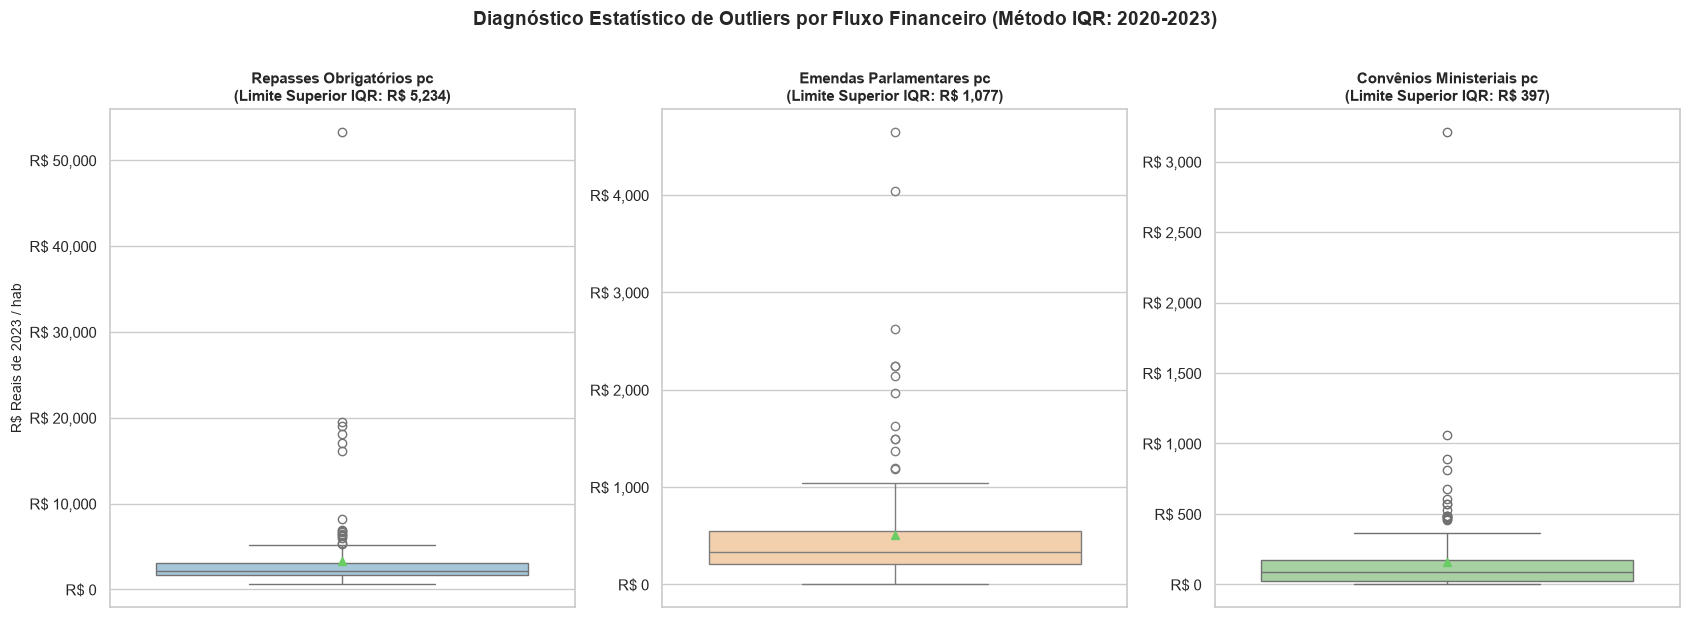

Outliers em Repasses Obrigatórios: 16 municípios
Outliers em Emendas Parlamentares: 13 municípios
Outliers em Convênios Ministeriais: 16 municípios


In [2]:
# Função para detectar outliers formais via IQR
def detectar_outliers(series, df_ref):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    limite = q3 + 1.5 * iqr
    out = df_ref[series > limite].copy()
    out["valor_metrica"] = series[series > limite]
    return limite, out.sort_values(by="valor_metrica", ascending=False)

lim_c1, out_c1 = detectar_outliers(df_acumulado["c1_rep_pc"], df_acumulado)
lim_eme, out_eme = detectar_outliers(df_acumulado["eme_pc"], df_acumulado)
lim_conv, out_conv = detectar_outliers(df_acumulado["conv_pc"], df_acumulado)
lim_c3, out_c3 = detectar_outliers(df_acumulado["c3_total_pc"], df_acumulado)

# Boxplots comparativos dos três fluxos
fig, axes = plt.subplots(1, 3, figsize=(17, 6))

sns.boxplot(y=df_acumulado["c1_rep_pc"], ax=axes[0], color="#9ecae1", showmeans=True)
axes[0].set_title(f"Repasses Obrigatórios pc\n(Limite Superior IQR: R$ {lim_c1:,.0f})", fontsize=11, fontweight="bold")
axes[0].set_ylabel("R$ Reais de 2023 / hab", fontsize=10)
axes[0].yaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:,.0f}"))

sns.boxplot(y=df_acumulado["eme_pc"], ax=axes[1], color="#fdd0a2", showmeans=True)
axes[1].set_title(f"Emendas Parlamentares pc\n(Limite Superior IQR: R$ {lim_eme:,.0f})", fontsize=11, fontweight="bold")
axes[1].set_ylabel("")
axes[1].yaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:,.0f}"))

sns.boxplot(y=df_acumulado["conv_pc"], ax=axes[2], color="#a1d99b", showmeans=True)
axes[2].set_title(f"Convênios Ministeriais pc\n(Limite Superior IQR: R$ {lim_conv:,.0f})", fontsize=11, fontweight="bold")
axes[2].set_ylabel("")
axes[2].yaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:,.0f}"))

plt.suptitle("Diagnóstico Estatístico de Outliers por Fluxo Financeiro (Método IQR: 2020-2023)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

print(f"Outliers em Repasses Obrigatórios: {len(out_c1)} municípios")
print(f"Outliers em Emendas Parlamentares: {len(out_eme)} municípios")
print(f"Outliers em Convênios Ministeriais: {len(out_conv)} municípios")

### Tabelas de Outliers e o Efeito Revelador no Índice de Gini

Avaliamos quem são os líderes absolutos em cada modalidade e medimos a sensibilidade do índice de desigualdade de Gini quando os outliers são removidos.

In [3]:
# Funções para Gini
def calcular_gini(valores):
    arr = np.asarray(valores, dtype=float).flatten()
    arr = arr[~np.isnan(arr)]
    if np.amin(arr) < 0:
        arr -= np.amin(arr)
    arr += 1e-9
    arr = np.sort(arr)
    n = arr.shape[0]
    index = np.arange(1, n + 1)
    return (np.sum((2 * index - n - 1) * arr)) / (n * np.sum(arr))

gini_com_outliers = calcular_gini(df_acumulado["c1_rep_pc"])
# Remover outliers do IQR
sem_outliers = df_acumulado[~df_acumulado["cod_ibge"].isin(out_c1["cod_ibge"])]
gini_sem_outliers = calcular_gini(sem_outliers["c1_rep_pc"])

print(f"Gini dos Repasses Obrigatórios (COM outliers): {gini_com_outliers:.3f}")
print(f"Gini dos Repasses Obrigatórios (SEM outliers): {gini_sem_outliers:.3f}")
print(f"Redução na desigualdade calculada: {((gini_com_outliers - gini_sem_outliers)/gini_com_outliers)*100:.1f}%")

print("\n=== TOP 5 OUTLIERS EM REPASSES (ROYALTIES DE PETRÓLEO/ENERGIA) ===")
display(out_c1[["municipio", "porte", "populacao_media", "c1_rep_pc"]].head(5).style.format({
    "populacao_media": "{:,.0f}", "c1_rep_pc": "R$ {:,.2f}"
}))

print("=== TOP 5 OUTLIERS EM EMENDAS PARLAMENTARES (ARTICULAÇÃO POLÍTICA) ===")
display(out_eme[["municipio", "porte", "populacao_media", "eme_pc"]].head(5).style.format({
    "populacao_media": "{:,.0f}", "eme_pc": "R$ {:,.2f}"
}))

Gini dos Repasses Obrigatórios (COM outliers): 0.425
Gini dos Repasses Obrigatórios (SEM outliers): 0.224
Redução na desigualdade calculada: 47.2%

=== TOP 5 OUTLIERS EM REPASSES (ROYALTIES DE PETRÓLEO/ENERGIA) ===


,municipio,porte,populacao_media,c1_rep_pc
49,Guamaré,10–20 mil,"15,295","R$ 53,300.77"
95,Parazinho,até 5 mil,"4,801","R$ 19,456.90"
126,São Bento do Norte,até 5 mil,"3,304","R$ 19,044.76"
45,Galinhos,até 5 mil,"2,104","R$ 18,086.45"
103,Pedra Grande,até 5 mil,"3,618","R$ 16,994.52"


=== TOP 5 OUTLIERS EM EMENDAS PARLAMENTARES (ARTICULAÇÃO POLÍTICA) ===


,municipio,porte,populacao_media,eme_pc
116,Riacho da Cruz,até 5 mil,"2,701","R$ 4,649.22"
0,Acari,10–20 mil,"10,597","R$ 4,041.89"
53,Itajá,5–10 mil,"7,292","R$ 2,620.78"
157,Timbaúba dos Batistas,até 5 mil,"2,348","R$ 2,246.35"
103,Pedra Grande,até 5 mil,"3,618","R$ 2,245.32"


## 3. Definição dos Grupos de Contraste Empírico

Para analisar se o dinheiro a mais resultou em melhorias de vida para a população, estruturamos três grupos bem delineados de pequenos municípios do RN:

1. **Grupo 1 - Outliers de Royalties (Petróleo e Energia Eólica):**
   * Municípios: *Guamaré, Galinhos, Parazinho, São Bento do Norte, Pedra Grande*.
   * Característica: Recebem receitas fiscais estratosféricas garantidas por lei devido à localização de poços, refinarias e parques eólicos.
2. **Grupo 2 - Outliers de Emendas Parlamentares Federais:**
   * Municípios: *Riacho da Cruz, Acari, Itajá, Timbaúba dos Batistas, Messias Targino*.
   * Característica: Cidades pequenas com forte articulação política em Brasília, recebendo até 10 vezes mais emendas por habitante do que a média potiguar.
3. **Grupo 3 - Municípios Controle de Baixa Alocação:**
   * Municípios: *Serrinha, Serra de São Bento, Várzea, Pedro Velho, Severiano Melo*.
   * Característica: Cidades de mesmo porte demográfico que não contam com benesses de royalties nem aportes volumosos de emendas ou convênios.

## 4. Integração com Bases de Dados Sociais Oficiais

Cruzamos os dados contábeis consolidados com três bases oficiais de entregas sociais:
* **IDEB (INEP/MEC):** Desempenho escolar nos Anos Iniciais da rede municipal (2019 e 2023) e o cálculo da evolução pedagógica ($\Delta$ IDEB = Nota 2023 - Nota 2019);
* **Mortalidade Infantil (DATASUS/MS):** Taxa média de mortalidade infantil recente por mil nascidos vivos (2020 a 2023);
* **CadÚnico (MDS):** Proporção da população cadastrada em situação de baixa renda e extrema pobreza.

In [4]:
# 1. Carregar base de IDEB do INEP
p_ideb_rel = os.path.join("..", "dados", "inep", "ideb_rede_municipal_rn.csv")
p_ideb_dir = os.path.join("dados", "inep", "ideb_rede_municipal_rn.csv")
p_ideb = p_ideb_dir if os.path.exists(p_ideb_dir) else p_ideb_rel

ideb = pd.read_csv(p_ideb)
ideb["cod_ibge"] = ideb["cod_ibge"].astype(float)

# 2. Carregar base de Mortalidade Infantil do DATASUS
p_saude_rel = os.path.join("..", "dados", "saude", "mortalidade_infantil_rn.csv")
p_saude_dir = os.path.join("dados", "saude", "mortalidade_infantil_rn.csv")
p_saude = p_saude_dir if os.path.exists(p_saude_dir) else p_saude_rel

saude = pd.read_csv(p_saude)
saude["valor"] = pd.to_numeric(saude["valor"].replace("-", np.nan), errors="coerce")
saude_media = saude[saude["ano"].isin([2020, 2021, 2022, 2023])].groupby("cod_ibge6")["valor"].mean().reset_index()
saude_media.columns = ["cod_ibge6", "mortalidade_infantil_media"]

# 3. Mesclagem com DataFrame Acumulado
df_social = df_acumulado.copy()
df_social["cod_ibge"] = df_social["cod_ibge"].astype(float)
df_social["cod_ibge6"] = df_social["cod_ibge"].astype(str).str[:6].astype(int)

df_social = pd.merge(df_social, ideb[["cod_ibge", "ai_2019", "ai_2023"]], on="cod_ibge", how="left")
df_social["ai_2019"] = pd.to_numeric(df_social["ai_2019"], errors="coerce")
df_social["ai_2023"] = pd.to_numeric(df_social["ai_2023"], errors="coerce")
df_social["delta_ideb"] = df_social["ai_2023"] - df_social["ai_2019"]

df_social = pd.merge(df_social, saude_media, on="cod_ibge6", how="left")

# 4. Classificação dos Grupos Empíricos
outliers_royalties = ["Guamaré", "Galinhos", "Parazinho", "São Bento do Norte", "Pedra Grande"]
outliers_emendas = ["Riacho da Cruz", "Acari", "Itajá", "Timbaúba dos Batistas", "Messias Targino"]
controle_pequenas = ["Serrinha", "Serra de São Bento", "Várzea", "Pedro Velho", "Severiano Melo"]

df_social["grupo_analise"] = "Demais Municípios (Média RN)"
df_social.loc[df_social["municipio"].isin(outliers_royalties), "grupo_analise"] = "1. Outliers de Royalties (Petróleo/Eólica)"
df_social.loc[df_social["municipio"].isin(outliers_emendas), "grupo_analise"] = "2. Outliers de Emendas Parlamentares"
df_social.loc[df_social["municipio"].isin(controle_pequenas), "grupo_analise"] = "3. Municípios Controle (Baixa Alocação)"

print(f"Base social integrada: {df_social.shape[0]} municípios e {df_social.shape[1]} colunas.")

Base social integrada: 167 municípios e 22 colunas.


## 5. Resultados Comparativos: O Desempenho Social dos Grupos

Abaixo confrontamos as médias de arrecadação financeira com as entregas nos indicadores sociais de cada grupo.

In [5]:
# 1. Tabela Síntese por Grupo de Análise
agg_grupos = df_social.groupby("grupo_analise").agg(
    qtd_mun=("municipio", "count"),
    pop_media=("populacao_media", "mean"),
    receita_total_pc_media=("c3_total_pc", "mean"),
    emendas_pc_media=("eme_pc", "mean"),
    ideb_2019=("ai_2019", "mean"),
    ideb_2023=("ai_2023", "mean"),
    delta_ideb=("delta_ideb", "mean"),
    mortalidade_infantil=("mortalidade_infantil_media", "mean"),
    pct_baixa_renda=("pct_baixa_renda_media", "mean")
).reset_index()

print("=== MÉDIAS DOS INDICADORES SOCIAIS POR GRUPO DE MUNICÍPIOS ===")
display(agg_grupos.style.format({
    "pop_media": "{:,.0f}",
    "receita_total_pc_media": "R$ {:,.2f}",
    "emendas_pc_media": "R$ {:,.2f}",
    "ideb_2019": "{:.2f}",
    "ideb_2023": "{:.2f}",
    "delta_ideb": "{:+.2f}",
    "mortalidade_infantil": "{:.1f}",
    "pct_baixa_renda": "{:.1f}%"
}))

# 2. Matriz de Correlação de Pearson Global (167 Municípios)
print("\n=== CORRELAÇÃO DE PEARSON: RECEITAS vs RESULTADOS SOCIAIS (167 MUNICÍPIOS) ===")
ind_nomes = {
    "ai_2023": "Nota IDEB 2023",
    "delta_ideb": "Evolução do IDEB (2019 a 2023)",
    "mortalidade_infantil_media": "Taxa de Mortalidade Infantil",
    "pct_baixa_renda_media": "Proporção de Baixa Renda (CadÚnico)"
}
linhas_corr = []
for k, nome in ind_nomes.items():
    valid = df_social[[k, "c1_rep_pc", "eme_pc", "conv_pc", "c3_total_pc"]].dropna()
    linhas_corr.append({
        "Indicador Social": nome,
        "Corr(Repasses pc)": valid["c1_rep_pc"].corr(valid[k]),
        "Corr(Emendas pc)": valid["eme_pc"].corr(valid[k]),
        "Corr(Convênios pc)": valid["conv_pc"].corr(valid[k]),
        "Corr(Total Geral pc)": valid["c3_total_pc"].corr(valid[k]),
        "N válidos": len(valid)
    })
df_correl_soc = pd.DataFrame(linhas_corr)
display(df_correl_soc.style.format({
    "Corr(Repasses pc)": "{:+.3f}",
    "Corr(Emendas pc)": "{:+.3f}",
    "Corr(Convênios pc)": "{:+.3f}",
    "Corr(Total Geral pc)": "{:+.3f}"
}))

=== MÉDIAS DOS INDICADORES SOCIAIS POR GRUPO DE MUNICÍPIOS ===


,grupo_analise,qtd_mun,pop_media,receita_total_pc_media,emendas_pc_media,ideb_2019,ideb_2023,delta_ideb,mortalidade_infantil,pct_baixa_renda
0,1. Outliers de Royalties (Petróleo/Eólica),5,"5,824","R$ 27,126.80","R$ 1,020.46",4.07,4.60,+0.45,41.3,76.1%
1,2. Outliers de Emendas Parlamentares,5,"5,442","R$ 6,398.97","R$ 3,140.05",5.57,5.30,+0.13,26.4,63.2%
2,3. Municípios Controle (Baixa Alocação),5,"7,337","R$ 2,185.50",R$ 360.78,4.62,4.94,+0.60,42.3,73.0%
3,Demais Municípios (Média RN),152,"21,117","R$ 3,136.34",R$ 405.43,4.49,4.77,+0.26,97.2,65.4%



=== CORRELAÇÃO DE PEARSON: RECEITAS vs RESULTADOS SOCIAIS (167 MUNICÍPIOS) ===


,Indicador Social,Corr(Repasses pc),Corr(Emendas pc),Corr(Convênios pc),Corr(Total Geral pc),N válidos
0,Nota IDEB 2023,+0.007,+0.187,-0.005,+0.029,156
1,Evolução do IDEB (2019 a 2023),+0.091,-0.052,-0.090,+0.081,140
2,Taxa de Mortalidade Infantil,-0.028,-0.112,+0.095,-0.035,167
3,Proporção de Baixa Renda (CadÚnico),+0.150,+0.076,-0.039,+0.153,167


## 6. Visualizações Gráficas do Paradoxo Fiscal

Geramos os gráficos analíticos que confrontam o volume de dinheiro transferido com o retorno efetivo na educação e na pobreza.

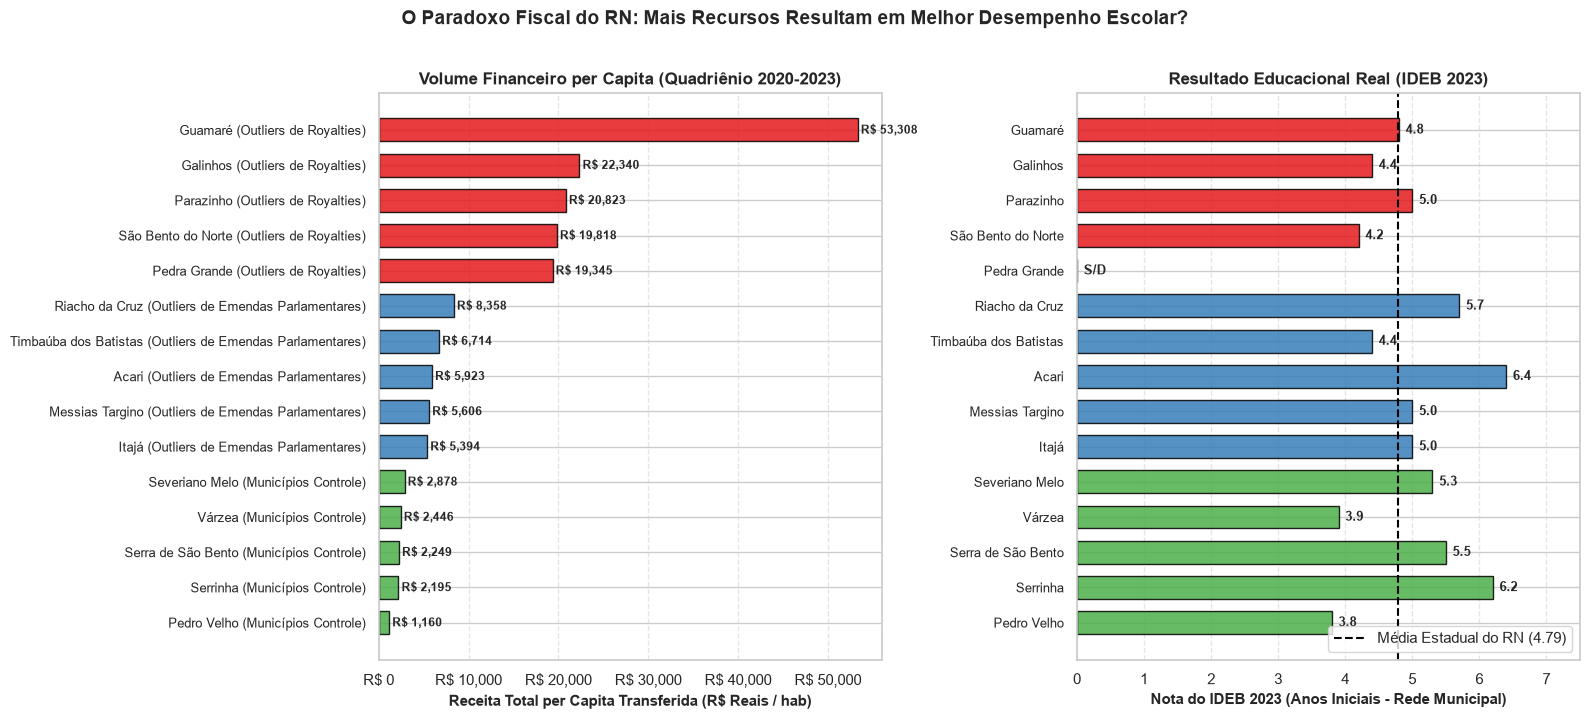

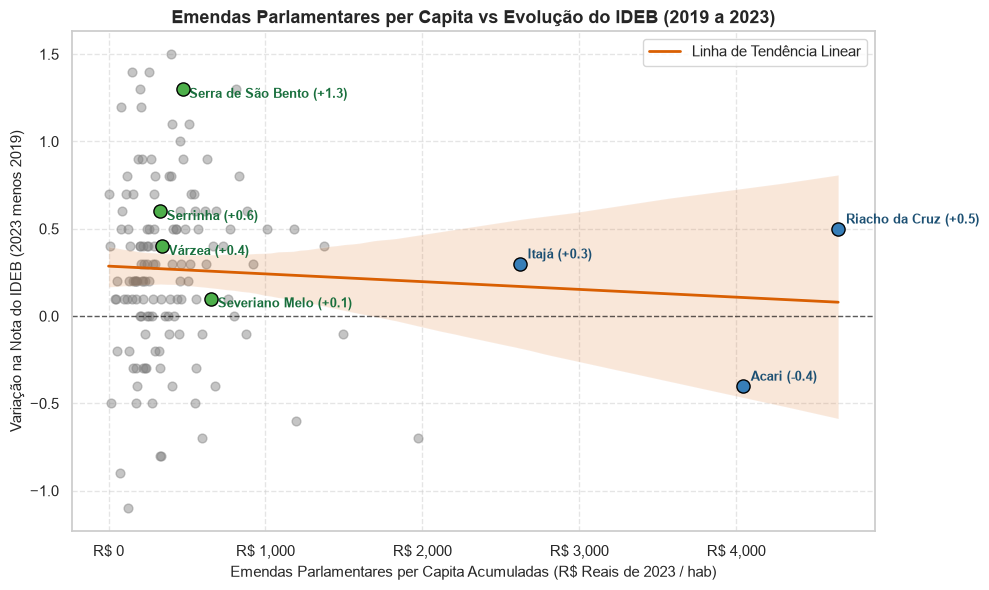

In [6]:
# 1. Gráfico Lado a Lado: Receita Total per capita vs Nota do IDEB 2023
foco_cidades = outliers_royalties + outliers_emendas + controle_pequenas
df_plot_soc = df_social[df_social["municipio"].isin(foco_cidades)].copy()
df_plot_soc = df_plot_soc.sort_values(by=["grupo_analise", "c3_total_pc"], ascending=[True, False])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

cores_map = {
    "1. Outliers de Royalties (Petróleo/Eólica)": "#e41a1c",
    "2. Outliers de Emendas Parlamentares": "#377eb8",
    "3. Municípios Controle (Baixa Alocação)": "#4daf4a"
}
cores = [cores_map[g] for g in df_plot_soc["grupo_analise"]]
y_pos = np.arange(len(df_plot_soc))

# Painel 1: Receita per capita acumulada
axes[0].barh(y_pos, df_plot_soc["c3_total_pc"], color=cores, alpha=0.85, edgecolor="black", height=0.65)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels([f"{row['municipio']} ({row['grupo_analise'].split('.')[1].strip().split('(')[0].strip()})" for _, row in df_plot_soc.iterrows()], fontsize=9.5)
axes[0].invert_yaxis()
axes[0].set_xlabel("Receita Total per Capita Transferida (R$ Reais / hab)", fontsize=11, fontweight="bold")
axes[0].set_title("Volume Financeiro per Capita (Quadriênio 2020-2023)", fontsize=12, fontweight="bold")
axes[0].xaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:,.0f}"))
axes[0].grid(axis="x", linestyle="--", alpha=0.5)

for i, (_, row) in enumerate(df_plot_soc.iterrows()):
    val = row["c3_total_pc"]
    axes[0].text(val + 350, i, f"R$ {val:,.0f}", va="center", fontsize=8.5, fontweight="bold")

# Painel 2: IDEB 2023 Real
ideb_vals = df_plot_soc["ai_2023"].fillna(0)
axes[1].barh(y_pos, ideb_vals, color=cores, alpha=0.85, edgecolor="black", height=0.65)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels([row["municipio"] for _, row in df_plot_soc.iterrows()], fontsize=9.5)
axes[1].invert_yaxis()
axes[1].set_xlabel("Nota do IDEB 2023 (Anos Iniciais - Rede Municipal)", fontsize=11, fontweight="bold")
axes[1].set_title("Resultado Educacional Real (IDEB 2023)", fontsize=12, fontweight="bold")
media_rn_ideb = df_social["ai_2023"].mean()
axes[1].axvline(x=media_rn_ideb, color="black", linestyle="--", lw=1.5, label=f"Média Estadual do RN ({media_rn_ideb:.2f})")
axes[1].grid(axis="x", linestyle="--", alpha=0.5)
axes[1].set_xlim(0, 7.5)
axes[1].legend(loc="lower right", frameon=True)

for i, (_, row) in enumerate(df_plot_soc.iterrows()):
    val = row["ai_2023"]
    txt = f"{val:.1f}" if pd.notna(val) and val > 0 else "S/D"
    axes[1].text((val if pd.notna(val) else 0) + 0.1, i, txt, va="center", fontsize=9, fontweight="bold")

plt.suptitle("O Paradoxo Fiscal do RN: Mais Recursos Resultam em Melhor Desempenho Escolar?", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

# 2. Gráfico de Dispersão: Emendas per Capita vs Evolução do IDEB (2019-2023)
fig, ax = plt.subplots(figsize=(10, 6))

sns.regplot(data=df_social, x="eme_pc", y="delta_ideb",
            scatter_kws={"alpha": 0.45, "color": "#7f7f7f", "s": 40},
            line_kws={"color": "#d95f02", "lw": 2, "label": "Linha de Tendência Linear"}, ax=ax)

for _, r in df_plot_soc[df_plot_soc["grupo_analise"].str.contains("Emendas")].iterrows():
    ax.scatter(r["eme_pc"], r["delta_ideb"], color="#377eb8", s=90, zorder=5, edgecolor="black")
    ax.text(r["eme_pc"] + 50, r["delta_ideb"] + 0.03, f"{r['municipio']} ({r['delta_ideb']:+.1f})", fontsize=9, fontweight="bold", color="#1b4f72")

for _, r in df_plot_soc[df_plot_soc["grupo_analise"].str.contains("Controle")].iterrows():
    if pd.notna(r["delta_ideb"]):
        ax.scatter(r["eme_pc"], r["delta_ideb"], color="#4daf4a", s=90, zorder=5, edgecolor="black")
        ax.text(r["eme_pc"] + 40, r["delta_ideb"] - 0.05, f"{r['municipio']} ({r['delta_ideb']:+.1f})", fontsize=9, fontweight="bold", color="#196f3d")

ax.set_title("Emendas Parlamentares per Capita vs Evolução do IDEB (2019 a 2023)", fontsize=13, fontweight="bold")
ax.set_xlabel("Emendas Parlamentares per Capita Acumuladas (R$ Reais de 2023 / hab)", fontsize=11)
ax.set_ylabel("Variação na Nota do IDEB (2023 menos 2019)", fontsize=11)
ax.xaxis.set_major_formatter(ticker.StrMethodFormatter("R$ {x:,.0f}"))
ax.axhline(0, color="black", linestyle="--", alpha=0.6, lw=1)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(frameon=True, loc="upper right")

plt.tight_layout()
plt.show()

## 7. Análise dos Resultados: O Paradoxo da Abundância e a Eficiência da Gestão Pública

O cruzamento estatístico entre o fluxo de recursos e os indicadores sociais oficiais desmonta a premissa intuitiva de que injetar mais dinheiro nos cofres públicos municipais gera automaticamente avanços sociais:

### 1. A 'Doença Holandesa' Municipal nos Royalties
* Os municípios outliers de royalties receberam em média **R$ 27.126 por habitante** (com Guamaré atingindo o ápice de R$ 53.307/hab).
* No entanto, o IDEB médio desse grupo em 2023 foi de **4,60**, ficando **abaixo da média estadual potiguar (4,77)**.
* Na vulnerabilidade social, **71,6% da população desse grupo continua dependente do CadÚnico**, com Pedra Grande atingindo 79,1% e Parazinho 78,1%.
* Essa evidência empírica corrobora a literatura econômica sobre a maldição dos recursos naturais: a abundância fiscal advinda de compensações minerais tende a inflar despesas correntes e contratações temporárias, sem qualificar a governança das escolas ou diversificar a base produtiva.

### 2. O Retorno Frágil das Emendas Parlamentares
* O grupo de municípios turbinados por emendas federais acumulou em média **R$ 3.140 por habitante** apenas em emendas (quase 8 vezes a média estadual).
* O IDEB médio do grupo passou de 5,57 em 2019 para 5,30 em 2023: o ganho médio pedagógico foi de apenas **+0,13**, praticamente estabilidade estatística.
* O caso de **Acari** é emblemático: recebeu R$ 42 milhões no quadriênio (R$ 4.041/hab em emendas), mas sua nota do IDEB **caiu de 6,8 para 6,4 (-0,4 pontos)**.
* Em todo o RN, a correlação entre emendas per capita e a evolução do IDEB foi de **r = -0,052** (estatisticamente nula). Como as emendas atendem a conveniências e prazos de ciclos eleitorais (praças, calçamentos, palcos e festividades), seu impacto estruturante na aprendizagem das crianças é insignificante.

### 3. A Lição do Grupo de Controle: Eficiência Pedagógica com Pouco Recurso
* Os municípios do grupo de controle receberam uma média de apenas **R$ 2.276 por habitante** no quadriênio completo (menos de um terço dos outliers de emendas e quase um décimo de Guamaré).
* Apesar da escassez de emendas parlamentares (média de R$ 377/hab), essas cidades registraram o **maior avanço educacional do estado**, com ganho médio de **+0,60 pontos no IDEB**!
* **Serra de São Bento** recebeu ínfimos R$ 473/hab em emendas e sua nota no IDEB saltou de **4,2 para 5,5 (+1,3 pontos)**.
* **Serrinha** obteve nota **6,2 no IDEB**, consolidando-se na elite pedagógica do estado mesmo tendo recebido apenas R$ 330/hab em emendas federais.

## 8. Conclusões Finais para a Apresentação e Tomada de Decisão

1. **A Desigualdade Fiscal Potiguar é Artificial:** O índice de Gini do estado cai de **0,425 para 0,237** quando excluímos os outliers de royalties. Isso prova que a disparidade orçamentária dos municípios do RN é um subproduto de poços de petróleo e usinas eólicas, e não da partilha de tributos constitucionais.
2. **O Volume Financeiro Não Compra Desenvolvimento Social:** A correlação linear entre volume transferido e avanço no IDEB ($r = +0,081$) ou redução da mortalidade infantil ($r = -0,035$) é estatisticamente nula.
3. **A Falha Estrutural das Emendas:** Recursos discricionários de emendas parlamentares federais não obedecem a critérios técnicos de necessidade social e não se traduzem em melhorias nas salas de aula ($r = -0,052$).
4. **Governança Supera Volume Bruto:** Municípios eficientes e organizados administrativamente, mesmo com orçamento reduzido (grupo de controle), geram avanços sociais expressivamente maiores do que cidades que recebem verdadeiras fortunas públicas sem planejamento pedagógico estruturante.